**`LangChain Agent`** 底层运行图架构正是 **`ReAct`** 。

**`ReAct`** 是 **`Reason + Action`** 的缩写，即“推理 + 行动”架构。其核心思想是：

1. **Reason**：大模型根据当前消息状态进行推理，判断是否需要调用工具；
2. **Action**：如果需要调用工具，则生成工具调用请求；
3. **Observation**：工具执行后，将执行结果以 **`ToolMessage`** 的形式返回给大模型；
4. **Loop**：大模型基于新的观察结果继续推理，决定是否继续调用工具；
5. **Final Answer**：当大模型不再发起工具调用时，生成最终回答，流程结束。

因此，**`ReAct`** 本质上是一个典型的 **“LLM → Tool → LLM → Tool → ... → LLM”** 循环结构。

本节分别使用两种方式实现该循环：

* **静态实现**：通过 **`add_conditional_edges()`** 在图结构中显式定义条件路由；
* **动态实现**：通过 **`Command(goto=...)`** 在节点返回值中触发运行时跳转。

## 1. 实现

### 1.1 静态实现

所谓“静态实现”，并不是指执行路径完全固定，而是指：

> **节点的下游候选集合在图编译阶段已经确定，运行时只是从这些候选节点中选择下一步。**

在本例中，**`llm_node`** 的下游候选节点是固定的：

* 如果大模型返回了 **`tool_calls`**，则进入 **`tool_node`**；
* 如果大模型没有返回 **`tool_calls`**，则进入 **`output_node`**。

也就是说，图结构在编译阶段已经知道 **`llm_node`** 可能流向 **`tool_node`** 或 **`output_node`**，运行时只负责判断具体走哪一条路径。

============================== -> ai_res <- ==============================
user_input:  帮我查询杭州当日天气和AI热点
final_answer:  两项查询都已完成 ✅

**🌤️ 杭州当日天气**
- 天气：晴朗
- 风力：东南风三级
- 气温：25~30 ℃（出行记得防晒补水）

**🤖 AI 领域热点**
- Anthropic 发布了 Claude Opus-4.8，但据反馈，通过 API 用中文向它发送“你是谁？”时，大多数情况下返回的却是“Qwen”或“Deepseek”。

需要我进一步查一下食品安全方面的热点，或者了解某个话题的更多细节吗？
================================ System Message ================================

如果工具调用失败，必须重新调用直至成功
================================ Human Message =================================

帮我查询杭州当日天气和AI热点
================================== Ai Message ==================================

我会同时查询杭州天气和 AI 领域热点。
Tool Calls:
  get_weather (call_00_0CkxyUN5tXrAmWiEapZn1347)
 Call ID: call_00_0CkxyUN5tXrAmWiEapZn1347
  Args:
    city: 杭州
  get_news (call_01_hPwUxwsboMiinEzf4rJ04849)
 Call ID: call_01_hPwUxwsboMiinEzf4rJ04849
  Args:
    domain: AI
================================= Tool Message =================================

网络波动，调式失败，请重试
================================= Too

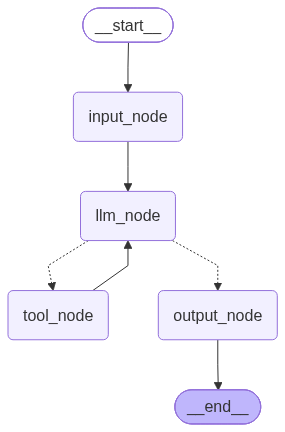

In [1]:
from typing import Literal
from langchain import messages
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import MessagesState
from langchain.messages import HumanMessage, ToolMessage, SystemMessage
from langchain.tools import tool
from langchain_deepseek import ChatDeepSeek
from IPython.display import display
from random import randint
from dotenv import load_dotenv

load_dotenv(override=True)

deepseek_model = ChatDeepSeek(
    model="deepseek-flash",
    extra_body={
        "thinking": {
            "type": "disabled"
        }
    }
)

@tool(parse_docstring=True)
def get_weather(city: str="北京"):
    """
    查询指定城市当日天气

    Args:
        city: 城市名称
    """
    return f"{city} 今天天气晴朗，东南风三级，气温 25~30 ℃"

@tool(parse_docstring=True)
def get_news(domain: Literal["AI", "食品安全"]):
    """
    查询特定领域的当日热点

    Args:
        domain: 特定领域
    """
    if domain == "AI":
        return "Anthropic 发布了 Claude Opus-4.8，但通过 API 用中文向它发送“你是谁？”时，大多数情况下返回的却是“Qwen”或“Deepseek”。"
    else:
        return "双汇发展子公司猪肉产品被抽检出抗生素超标37.5倍"

my_tools = [get_weather, get_news]

model_with_tools = deepseek_model.bind_tools(tools=my_tools)

class OverAllState(MessagesState):
    user_input: str
    final_answer: str

def input_node(state: OverAllState) -> OverAllState:
    return {
        "messages": [HumanMessage(state["user_input"])],
    }

def llm_node(state: OverAllState) -> OverAllState:
    messages = state["messages"]
    # 调用工具
    ai_msg = model_with_tools.invoke(messages)
    return {
        "messages": [ai_msg],
    }

def tool_node(state: OverAllState) -> OverAllState:
    messages = state["messages"]
    ai_msg = messages[-1]
    tool_calls = ai_msg.tool_calls
    # 失败概率，6表示 60% 概率失败，7 -> 70%，8 -> 80%，依次类推
    fail_prob = 6
    for tool_call in tool_calls:
        if tool_call["name"] == "get_weather":
            # 生成 0 ~ 9的随机数
            if randint(0, 9) < fail_prob:
                messages.append(
                    ToolMessage(
                        content="网络波动，调式失败，请重试",
                        tool_call_id = tool_call["id"],
                    )
                )
            else:
                messages.append(get_weather.invoke(tool_call))
        elif tool_call["name"] == "get_news":
            if randint(0, 9) < fail_prob:
                messages.append(
                    ToolMessage(
                        content="网络波动，调式失败，请重试",
                        tool_call_id = tool_call["id"],
                    )
                )
            else:
                messages.append(get_news.invoke(tool_call))
        else:
            messages.append(
                ToolMessage(
                    content="工具名称错误，调用失败，请重试",
                    tool_call_id = tool_call["id"],
                )
            )
    return {
        "messages": messages,
    }

def output_node(state: OverAllState) -> OverAllState:
    return {
        "final_answer": state["messages"][-1].content
    }

def router(state: OverAllState) -> Literal["tool_node", "output_node"]:
    messages = state["messages"]
    lst_msg = messages[-1]

    if lst_msg.tool_calls:
        return "tool_node"
    return "output_node"

builder = StateGraph(state_schema=OverAllState)
builder.add_node("input_node", input_node)
builder.add_node("llm_node", llm_node)
builder.add_node("tool_node", tool_node)
builder.add_node("output_node", output_node)

builder.add_edge(START, "input_node")
builder.add_edge("input_node", "llm_node")
builder.add_conditional_edges(
    "llm_node",
    router
)
builder.add_edge("tool_node", "llm_node")
builder.add_edge("output_node", END)

graph = builder.compile()
ai_res = graph.invoke({
    "user_input": "帮我查询杭州当日天气和AI热点",
    "messages": [SystemMessage("如果工具调用失败，必须重新调用直至成功")]
})
food_safety_res = graph.invoke({
    "user_input": "帮我查询当日天气和食品安全相关的热点",
    "messages": [SystemMessage("如果工具调用失败，必须重新调用直至成功")]
})

print('=' * 30, '-> ai_res <-', '=' * 30)
print("user_input: ", ai_res["user_input"])
print("final_answer: ", ai_res["final_answer"])
for msg in ai_res["messages"]:
    msg.pretty_print()

print('=' * 30, '-> food_safety_res <-', '=' * 30)
print("user_input: ", food_safety_res["user_input"])
print("final_answer: ", food_safety_res["final_answer"])
for msg in food_safety_res["messages"]:
    msg.pretty_print()

display(graph)

本例运行图中的循环结构如下：

```text
START
  ↓
input_node
  ↓
llm_node
  ├── 有 tool_calls → tool_node → llm_node
  └── 无 tool_calls → output_node → END
```

其中，循环发生在：

```text
llm_node → tool_node → llm_node
```

只要大模型持续返回工具调用，流程就会不断回到 **`llm_node`**，形成 **`ReAct`** 循环。

需要注意的是，本例中“工具调用失败后继续重试”主要依赖这条系统提示词：

```python
SystemMessage("如果工具调用失败，必须重新调用直至成功")
```

也就是说，是否继续重试，在当前实现中主要由大模型决定，而不是由程序逻辑强制保证。

### 1.2. 动态实现

除了静态路由，我们还可以利用 **`Command`** 在运行时动态指定下一个要执行的节点。

在本节的实现中，**`llm_node`** 借助 **`Command`** 在返回值中同时完成两件事：

- 更新状态；
- 控制下一步的跳转。

这里的 **动态** 是指：

> **节点在运行时，根据自身的执行结果，直接返回“状态更新 + 下一跳控制指令”。**

在本例中，**`llm_node`** 调用大模型后，会根据返回结果决定后续流程：

* 如果 **`ai_msg.tool_calls`** 不为空，则 **`goto="tool_node"`**；
* 如果 **`ai_msg.tool_calls`** 为空，则 **`goto="output_node"`**。

这样一来，路由逻辑就被内聚在 **`llm_node`** 节点，不再需要额外定义 **`router()`** 函数，也不再需要调用 **`add_conditional_edges()`** 从 **`llm_node`** 添加条件边。

============================== -> ai_res <- ==============================
user_input:  帮我查询杭州当日天气和AI热点
final_answer:  查询完成，结果如下：

## 🌤️ 杭州当日天气
- **天气**：晴朗
- **风力**：东南风三级
- **气温**：25~30 ℃

适合户外活动，注意防晒补水。

## 🤖 AI 热点
- **Anthropic 发布 Claude Opus-4.8**：但有个值得关注的现象——通过 API 用中文向它发送“你是谁？”时，大多数情况下返回的却是“Qwen”或“Deepseek”。这可能暗示其模型训练数据或中文能力来源存在争议，值得进一步观察。

需要我帮你查食品安全方面的热点吗？
================================ System Message ================================

如果工具调用失败，必须重新调用直至成功
================================ Human Message =================================

帮我查询杭州当日天气和AI热点
================================== Ai Message ==================================

我这就帮你查询杭州天气和 AI 热点。
Tool Calls:
  get_weather (call_00_hySt8P8V6QNTgXEuad3p0855)
 Call ID: call_00_hySt8P8V6QNTgXEuad3p0855
  Args:
    city: 杭州
  get_news (call_01_VDWahFL8rhd4i0kv6qdg7018)
 Call ID: call_01_VDWahFL8rhd4i0kv6qdg7018
  Args:
    domain: AI
================================= Tool Message =================================
Name: get_weat

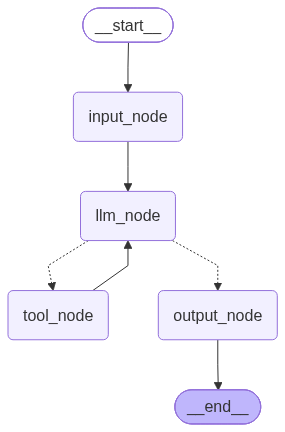

In [2]:
from typing import Literal
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import MessagesState
from langgraph.types import Command
from langchain.messages import HumanMessage, ToolMessage, SystemMessage
from langchain.tools import tool
from langchain_deepseek import ChatDeepSeek
from IPython.display import display

from random import randint
from dotenv import load_dotenv
load_dotenv(override=True)

deep_model = ChatDeepSeek(
    model="deepseek-flash",
    extra_body={
        "thinking": {
            "type": "disabled"
        }
    }
)

@tool(parse_docstring=True)
def get_weather(city: str="北京"):
    """
    查询指定城市当日天气

    Args:
        city: 城市名称
    """
    return f"{city} 今天天气晴朗，东南风三级，气温 25~30 ℃"

@tool(parse_docstring=True)
def get_news(domain: Literal["AI", "食品安全"]):
    """
    查询特定领域的当日热点

    Args:
        domain: 特定领域
    """
    if domain == "AI":
        return "Anthropic 发布了 Claude Opus-4.8，但通过 API 用中文向它发送“你是谁？”时，大多数情况下返回的却是“Qwen”或“Deepseek”。"
    else:
        return "双汇发展子公司猪肉产品被抽检出抗生素超标37.5倍"

mytools = [get_weather, get_news]

model_with_tools = deep_model.bind_tools(tools=mytools)

# 继承了 MessagesState
class OverAllState(MessagesState):
    user_input: str
    final_answer: str

def input_node(state: OverAllState) -> OverAllState:
    return {
        "messages": [HumanMessage(state["user_input"])],
    }

def llm_node(state: OverAllState) -> Command[Literal["tool_node", "output_node"]]:
    messages = state["messages"]
    ai_msg = model_with_tools.invoke(messages)
    if ai_msg.tool_calls:
        goto_res = "tool_node"
    else:
        goto_res = "output_node"

    return Command(
        goto=goto_res,
        update={
            "messages": [ai_msg],
        }
    )

def tool_node(state: OverAllState) -> OverAllState:
    messages = state["messages"]
    ai_msg = messages[-1]
    tool_calls = ai_msg.tool_calls
    # 失败率 6 表示60%
    fail_prob = 6
    for tool_call in tool_calls:
        if tool_call["name"] == "get_weather":
            if randint(0, 9) < fail_prob:
                messages.append(
                    ToolMessage(
                        content="网络波动，调用失败，请重试",
                        tool_call_id = tool_call["id"],
                    )
                )
            else:
                messages.append(get_weather.invoke(tool_call))
        elif tool_call["name"] == "get_news":
            if randint(0, 9) < fail_prob:
                messages.append(
                    ToolMessage(
                        content="网络波动，调用失败，请重试",
                        tool_call_id = tool_call["id"],
                    )
                )
            else:
                messages.append(get_news.invoke(tool_call))
        else:
            messages.append(
                ToolMessage(
                    content="工具名称错误，调用失败，请重试",
                    tool_call_id = tool_call["id"],
                )
            )
    return {
        "messages": messages,
    }

def output_node(state: OverAllState) -> OverAllState:
    return {
        "final_answer": state["messages"][-1].content
    }

builder = StateGraph(state_schema=OverAllState)
builder.add_node("input_node", input_node)
builder.add_node("llm_node", llm_node)
builder.add_node("tool_node", tool_node)
builder.add_node("output_node", output_node)

builder.add_edge(START, "input_node")
builder.add_edge("input_node", "llm_node")
builder.add_edge("tool_node", "llm_node")
builder.add_edge("output_node", END)

graph = builder.compile()
ai_res = graph.invoke({
    "user_input": "帮我查询杭州当日天气和AI热点",
    "messages": [SystemMessage("如果工具调用失败，必须重新调用直至成功")]
})
food_safety_res = graph.invoke({
    "user_input": "帮我查询当日天气和食品安全相关的热点",
    "messages": [SystemMessage("如果工具调用失败，必须重新调用直至成功")]
})

print('=' * 30, '-> ai_res <-', '=' * 30)
print("user_input: ", ai_res["user_input"])
print("final_answer: ", ai_res["final_answer"])
for msg in ai_res["messages"]:
    msg.pretty_print()

print('=' * 30, '-> food_safety_res <-', '=' * 30)
print("user_input: ", food_safety_res["user_input"])
print("final_answer: ", food_safety_res["final_answer"])
for msg in food_safety_res["messages"]:
    msg.pretty_print()

display(graph)

#### 小结

|            | 静态实现                               | 动态实现                   |
| ---------- | -------------------------------------- | -------------------------- |
| 路由位置   | 路由逻辑在独立的 **`router()`** 函数中 | 路由逻辑写在节点返回值中   |
| 图结构表达 | 显式声明条件边，更直观                 | 控制逻辑更内聚，代码更紧凑 |
| 适合场景   | 路由规则独立、希望图结构更清晰         | 节点执行结果直接决定下一跳 |

两种方式都能实现 **`ReAct`** 循环，本质区别不在于是否能循环，而在于：

> **路由逻辑写在哪里。**

* 基于 **`add_conditional_edges()`** 的静态实现：把控制逻辑放在图结构定义阶段；
* 基于 **`Command(goto=...)`** 的动态实现：把控制逻辑放在节点返回值中。

## 2. 引入递归限制
在存在循环结构的图中，如果没有合理的停止条件，运行图可能会一直循环执行。为了避免无限循环，**`LangGraph`** 提供了**递归限制**机制，用于限制单次图运行过程中允许执行的最大 **`SuperStep`** 数量。

当运行图在达到停止条件之前耗尽允许的最大步数时，**`LangGraph`** 会抛出 **`GraphRecursionError`**。开发者既可以在图内部提前检测剩余步数并优雅退出，也可以在图外部捕获异常并集中处理。

### 2.1. 步骤计数器
**`config`** 的元数据中记录了当前节点所在的 **`SuperStep`** 序号，可以通过下面的方式获取：

```python
config["metadata"]["langgraph_step"]
```


2026-10-20 16:21:06.165 | INFO     | __main__:node_a:12 - 1
2026-10-20 16:21:06.166 | INFO     | __main__:node_b:16 - 2
2026-10-20 16:21:06.166 | INFO     | __main__:node_c:20 - 3


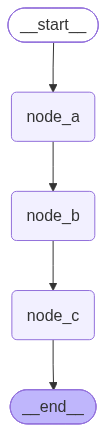

In [1]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END
from langgraph.config import RunnableConfig
from loguru import logger
from IPython.display import display

class EmptyState(TypedDict):
    pass

def node_a(state: EmptyState, config: RunnableConfig) -> EmptyState | None:
    cur_step = config["metadata"]["langgraph_step"]
    logger.info(cur_step)

def node_b(state: EmptyState, config: RunnableConfig) -> EmptyState | None:
    cur_step = config["metadata"]["langgraph_step"]
    logger.info(cur_step)

def node_c(state: EmptyState, config: RunnableConfig) -> EmptyState | None:
    cur_step = config["metadata"]["langgraph_step"]
    logger.info(cur_step)

builder = StateGraph(state_schema=EmptyState)
builder.add_node("node_a", node_a)
builder.add_node("node_b", node_b)
builder.add_node("node_c", node_c)

builder.add_edge(START, "node_a")
builder.add_edge("node_a", "node_b")
builder.add_edge("node_b", "node_c")
builder.add_edge("node_c", END)

graph = builder.compile()
graph.invoke({})

display(graph)

### 2.2. 配置**递归限制**

**`recursion_limit`** 表示单次图运行过程中允许执行的最大 **`SuperStep`** 数量。可以在调用运行图时通过 **`config`** 显式配置：

```python
graph.invoke(input, config={"recursion_limit": 10})
```

需要注意的是，**`recursion_limit` 的默认值可能随版本变化、运行环境切换而变化**。

(1) 优雅退出：主动方法（Proactive Approach）

2026-10-20 16:33:55.204 | INFO     | __main__:loop_node:14 - loop_node, cur_step: 1, remaining_step: 9
2026-10-20 16:33:55.205 | INFO     | __main__:loop_node:14 - loop_node, cur_step: 2, remaining_step: 8
2026-10-20 16:33:55.207 | INFO     | __main__:loop_node:14 - loop_node, cur_step: 3, remaining_step: 7
2026-10-20 16:33:55.208 | INFO     | __main__:loop_node:14 - loop_node, cur_step: 4, remaining_step: 6
2026-10-20 16:33:55.209 | INFO     | __main__:loop_node:14 - loop_node, cur_step: 5, remaining_step: 5
2026-10-20 16:33:55.210 | INFO     | __main__:loop_node:14 - loop_node, cur_step: 6, remaining_step: 4
2026-10-20 16:33:55.211 | INFO     | __main__:loop_node:14 - loop_node, cur_step: 7, remaining_step: 3
2026-10-20 16:33:55.212 | INFO     | __main__:loop_node:14 - loop_node, cur_step: 8, remaining_step: 2
2026-10-20 16:33:55.212 | INFO     | __main__:router:19 - 当前可用超步：2, 已不足2步，终止运行图


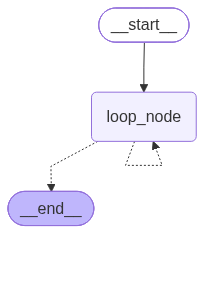

In [2]:
from typing import TypedDict, Literal
from langgraph.graph import StateGraph, START, END
from langgraph.config import RunnableConfig
from langgraph.managed import RemainingSteps
from loguru import logger
from IPython.display import display

class OverAllState(TypedDict):
    remaining_steps: RemainingSteps

def loop_node(state: OverAllState, config: RunnableConfig) -> OverAllState | None:
    cur_step = config["metadata"]["langgraph_step"]
    remaining_step = state["remaining_steps"]
    logger.info("loop_node, cur_step: {}, remaining_step: {}", cur_step, remaining_step)

def router(state: OverAllState) -> Literal["loop_node", END]:
    remaining_steps = state["remaining_steps"]
    if remaining_steps < 3:
        logger.info("当前可用超步：{}, 已不足2步，终止运行图", remaining_steps)
        return END
    return "loop_node"

builder = StateGraph(state_schema=OverAllState)
builder.add_node("loop_node", loop_node)

builder.add_edge(START, "loop_node")
builder.add_conditional_edges("loop_node", router)
graph = builder.compile()
graph.invoke({}, config={"recursion_limit": 10})

display(graph)

(2) 异常中断：被动方法（Reactive Approach）

2026-10-20 17:15:54.552 | INFO     | __main__:loop_node:13 - loop_node, cur_step: 1
2026-10-20 17:15:54.553 | INFO     | __main__:loop_node:13 - loop_node, cur_step: 2
2026-10-20 17:15:54.555 | INFO     | __main__:loop_node:13 - loop_node, cur_step: 3
2026-10-20 17:15:54.556 | INFO     | __main__:loop_node:13 - loop_node, cur_step: 4
2026-10-20 17:15:54.557 | INFO     | __main__:loop_node:13 - loop_node, cur_step: 5
2026-10-20 17:15:54.558 | INFO     | __main__:loop_node:13 - loop_node, cur_step: 6
2026-10-20 17:15:54.559 | INFO     | __main__:loop_node:13 - loop_node, cur_step: 7
2026-10-20 17:15:54.560 | INFO     | __main__:loop_node:13 - loop_node, cur_step: 8
2026-10-20 17:15:54.561 | INFO     | __main__:loop_node:13 - loop_node, cur_step: 9
2026-10-20 17:15:54.561 | INFO     | __main__:loop_node:13 - loop_node, cur_step: 10
2026-10-20 17:15:54.562 | INFO     | __main__:<module>:24 - 超步数量已经达到最大限制，抛出异常：Recursion limit of 10 reached without hitting a stop condition. You can increase 

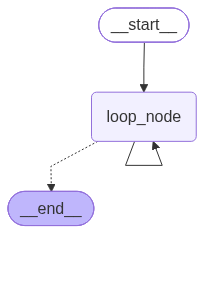

In [3]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END
from langgraph.errors import GraphRecursionError
from langgraph.config import RunnableConfig
from loguru import logger
from IPython.display import display

class EmptyState(TypedDict):
    pass

def loop_node(state: EmptyState, config: RunnableConfig) -> EmptyState | None:
    cur_step= config["metadata"]["langgraph_step"]
    logger.info("loop_node, cur_step: {}", cur_step)

builder = StateGraph(state_schema=EmptyState)
builder.add_node("loop_node", loop_node)
builder.add_edge(START, "loop_node")
builder.add_edge("loop_node", "loop_node")

graph = builder.compile()
try:
    graph.invoke({}, config={"recursion_limit": 10})
except GraphRecursionError as e:
    logger.info("超步数量已经达到最大限制，抛出异常：{}",e)

display(graph)

主动方法和被动方法的最大区别在于：

> **主动方法是在图内部提前处理递归限制；被动方法是在图外部捕获`递归限制异常`。**

| 方法                                 | 超限检测     | 处理方法                               | 控制流               |
| :----------------------------------- | :----------- | :------------------------------------- | :------------------- |
| 主动(借助 **`RemainingSteps`**)      | 达到限制之前 | 在图结构内部通过条件路由处理           | 图继续运行，正常结束 |
| 被动(捕获 **`GraphRecursionError`**) | 超出限制之后 | 图结构外部，通过 **`try/except`** 处理 | 图运行被异常中断     |

**主动方法的优势：**

- 在图内部实现优雅降级
- 可以将中间状态保存到检查点中
- 通过返回部分结果改善用户体验
- 图可以正常完成，不会抛出异常

**被动方法的优势：**

- 实现更简单
- 不需要修改图的内部逻辑
- 可以集中处理错误

实际开发中，如果循环结构本身是业务逻辑的一部分，例如 **ReAct 循环、多轮反思、自我修正、工具调用重试** 等，更推荐使用主动方法，在图内部提前处理递归限制。

如果只是为了兜底防止无限循环，也可以保留被动方法，在最外层捕获 **`GraphRecursionError`**，作为最后一道防线。

#### 注意

1. 一个节点可以有多个出边。此时，这些出边对应的目标节点会在下一个超步中**并行**执行。
2. 除了上述方式，条件边还可以通过在节点中返回 **`Command(goto=...)`** 来实现，虽然方式不同，但边的性质和作用完全一致。
3. 在实际开发中，建议同一个节点尽量只选择一种路由机制：
   - 要么使用普通边，固定流转；
   - 要么使用条件边或 **`Command(goto=...)`**，动态流转。

不要在同一个节点上同时混用普通边和动态路由，否则多个路径可能同时生效，最终导致运行图逻辑混乱，与预期不符。